In [1]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
import torch.nn as nn
import torchvision.models as models
from torch.cuda.amp import GradScaler, autocast

In [2]:
import numpy as np
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt


In [38]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.485, 0.456, 0.406],
                         std = [0.229, 0.224, 0.225])
    ])
    

In [39]:
dataset = datasets.ImageFolder(
    root = r"D:\hyper-kvasir-labeled-images-extracted\labeled-images\lower-gi-tract",
    transform = transform
)

In [40]:
dataset.classes

['bbps-0-1',
 'bbps-2-3',
 'cecum',
 'dyed-lifted-polyps',
 'dyed-resection-margins',
 'hemorrhoids',
 'ileum',
 'impacted-stool',
 'polyps',
 'retroflex-rectum',
 'ulcerative-colitis-grade-0-1',
 'ulcerative-colitis-grade-1',
 'ulcerative-colitis-grade-1-2',
 'ulcerative-colitis-grade-2',
 'ulcerative-colitis-grade-2-3',
 'ulcerative-colitis-grade-3']

In [41]:
dataset.class_to_idx

{'bbps-0-1': 0,
 'bbps-2-3': 1,
 'cecum': 2,
 'dyed-lifted-polyps': 3,
 'dyed-resection-margins': 4,
 'hemorrhoids': 5,
 'ileum': 6,
 'impacted-stool': 7,
 'polyps': 8,
 'retroflex-rectum': 9,
 'ulcerative-colitis-grade-0-1': 10,
 'ulcerative-colitis-grade-1': 11,
 'ulcerative-colitis-grade-1-2': 12,
 'ulcerative-colitis-grade-2': 13,
 'ulcerative-colitis-grade-2-3': 14,
 'ulcerative-colitis-grade-3': 15}

In [42]:
len(dataset)

7210

In [9]:
len(dataset[0])

2

In [43]:
from collections import Counter

label_counts = Counter([label for _, label in dataset.samples])

for class_name, idx in dataset.class_to_idx.items():
    print(f"{class_name}: {label_counts[idx]} images")

bbps-0-1: 646 images
bbps-2-3: 1148 images
cecum: 1009 images
dyed-lifted-polyps: 1002 images
dyed-resection-margins: 989 images
hemorrhoids: 6 images
ileum: 9 images
impacted-stool: 131 images
polyps: 1028 images
retroflex-rectum: 391 images
ulcerative-colitis-grade-0-1: 35 images
ulcerative-colitis-grade-1: 201 images
ulcerative-colitis-grade-1-2: 11 images
ulcerative-colitis-grade-2: 443 images
ulcerative-colitis-grade-2-3: 28 images
ulcerative-colitis-grade-3: 133 images


In [44]:
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
import torch

In [45]:
train_size = int(0.8*len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [46]:
#dataset.samples gives us a list of tuples (filepath, class_idx)

In [47]:
cecum_idx = dataset.class_to_idx['cecum']
train_labels = [dataset.samples[i][1] for i in train_dataset.indices]
binary_train_labels = [1 if label == cecum_idx else 0 for label in train_labels]

In [48]:
binary_train_labels[:5]

[0, 1, 0, 0, 0]

In [49]:
train_labels[:5]

[4, 2, 1, 1, 9]

In [50]:
len(dataset)

7210

In [51]:
n_cecum = sum(binary_train_labels)
n_non_cecum = len(binary_train_labels) - n_cecum

In [52]:
n_cecum

774

In [53]:
n_non_cecum

4994

In [54]:
weights = [1/n_cecum if label == 1 else 1/n_non_cecum for label in binary_train_labels]
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

In [55]:
train_loader = DataLoader(
     train_dataset,
     batch_size = 32,
     sampler = sampler,
     num_workers = 4,
     pin_memory = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = 32,
    shuffle = False,
    num_workers = 4,
    pin_memory = True
)



In [56]:
print(len(train_dataset))
print(len(val_dataset))

5768
1442


In [57]:
model = models.resnet50(weights = models.ResNet50_Weights.IMAGENET1K_V2)

In [58]:

#freeze all the layers
for param in model.parameters():
    param.requires_grad = False

#unfreeze the last 20 
for param in list(model.parameters())[-20:]:
    param.requires_grad = True

model.fc = nn.Sequential(
    nn.Linear(2048,256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256,1),
    nn.Sigmoid(),
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)



True

In [60]:
for name, param in model.named_parameters():
    if not param.requires_grad:
        print(f"{name}: {param.shape}")

conv1.weight: torch.Size([64, 3, 7, 7])
bn1.weight: torch.Size([64])
bn1.bias: torch.Size([64])
layer1.0.conv1.weight: torch.Size([64, 64, 1, 1])
layer1.0.bn1.weight: torch.Size([64])
layer1.0.bn1.bias: torch.Size([64])
layer1.0.conv2.weight: torch.Size([64, 64, 3, 3])
layer1.0.bn2.weight: torch.Size([64])
layer1.0.bn2.bias: torch.Size([64])
layer1.0.conv3.weight: torch.Size([256, 64, 1, 1])
layer1.0.bn3.weight: torch.Size([256])
layer1.0.bn3.bias: torch.Size([256])
layer1.0.downsample.0.weight: torch.Size([256, 64, 1, 1])
layer1.0.downsample.1.weight: torch.Size([256])
layer1.0.downsample.1.bias: torch.Size([256])
layer1.1.conv1.weight: torch.Size([64, 256, 1, 1])
layer1.1.bn1.weight: torch.Size([64])
layer1.1.bn1.bias: torch.Size([64])
layer1.1.conv2.weight: torch.Size([64, 64, 3, 3])
layer1.1.bn2.weight: torch.Size([64])
layer1.1.bn2.bias: torch.Size([64])
layer1.1.conv3.weight: torch.Size([256, 64, 1, 1])
layer1.1.bn3.weight: torch.Size([256])
layer1.1.bn3.bias: torch.Size([256])
l

In [ ]:
n_cecum = sum(binary_train_labels)
n_non_cecum = len(binary_train_labels) - n_cecum
pos_weight = torch.tensor([n_non_cecum/n_cecum]).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight = pos_weight)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr = 1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode = 'min', factor = 0.5, patience = 3
)

scaler = GradScaler()

num_epochs = 20

for epoch in range(num_epochs):
    #training

    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        binary = (labels == cecum_idx).float().to(device)

        optimizer.zero_grad()

        with autocast():
            outputs = model(images).squeeze()
            loss = criterion(outputs, binary)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    #validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    tp = 0 #true positives
    fn = 0 #false negatives

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            binary = (labels == cecum_idx).float().to(device)
            with autocast():
                outputs = model(images).squeeze()
                loss = criterion(outputs, binary)

            val_loss += loss.item()

            preds = (torch.sigmoid(outputs) > 0.5).float()
            correct += (preds == binary).sum().item()
            total += binary.size(0) #batch size
            tp += ((preds == 1) & (binary == 1)).sum().item()
            fn += ((preds == 0) & (binary == 1)).sum().item()


    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    accuracy = correct/total
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

    scheduler.step(avg_val_loss)


    print(f"Epoch {epoch + 1}/{num_epochs} | Train loss: {avg_train_loss:.4f} | Val loss: {avg_val_loss:.4f} | Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | LR: {optimizer.param_groups[0]['lr']:.2e")
    


In [3]:
#use grad-cam to see how the model decided its outputs
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model2 = models.resnet50(weights=None)
model2.fc = nn.Sequential(
    nn.Linear(2048, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1),
)

model2.load_state_dict(torch.load('best_model.pth', map_location = device))

<All keys matched successfully>

In [4]:
#target the last convolutional layer

target_layers = [model2.layer4[-1]]
cam = GradCAM(model = model2, target_layers = target_layers)

#load image
img_path = r"D:\hyper-kvasir-labeled-images-extracted\labeled-images\lower-gi-tract\cecum\0a4c2cc2-a86f-4cac-84ca-942b17a6e6db.jpg"
pil_image = Image.open(img_path).convert('RGB')

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.485, 0.456, 0.406],
                         std = [0.229, 0.224, 0.225],)
])

input_tensor = transform(pil_image).unsqueeze(0) #adds a batch dimension

grayscale_cam = cam(input_tensor = input_tensor, targets = None)

#the overlay requires image to be in float32 with pixel values between 0 and 1
#unlike the normalized values for the model

original = np.array(pil_image.resize((224,224)))/255.0
original = original.astype(np.float32)

#overlay onto the image
visualization = show_cam_on_image(original, grayscale_cam[0], use_rgb = True)



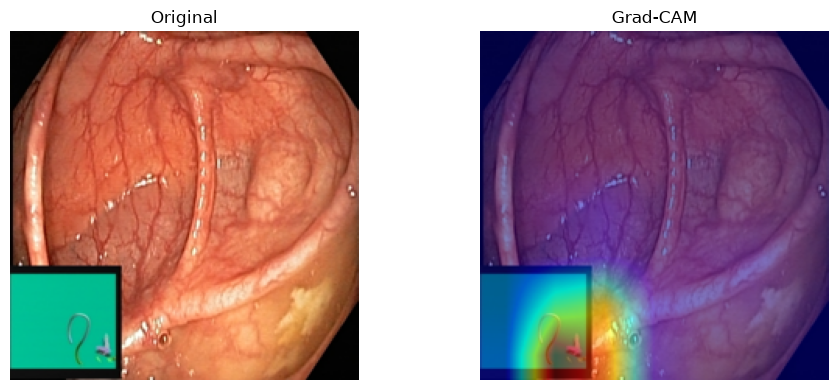

In [5]:
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
plt.imshow(pil_image.resize((224,224)))
plt.title('Original')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title('Grad-CAM')
plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
model2.eval()
model2.to(device)
with torch.no_grad():
    with torch.autocast(device_type = device.type):
        output = model2(input_tensor.to(device)).squeeze()
    prob = torch.sigmoid(output).item()

    prediction = 'cecum' if prob > 0.5 else 'not cecum'

    print(f"Raw logit: {output.item():.4f}")
    print(f"Probability: {prob:.4f}")
    print(f"Prediction: {prediction}")

Raw logit: 2.6641
Probability: 0.9351
Prediction: cecum


In [94]:
#so the heatmaps indicate that the model simply learned the scope guide images at the bottom left hand corner
#need to white these out and try training the model again
test_image = pil_image.resize((224,224))
img_array = np.array(test_image)
print(f"Img shape: {img_array.shape}")

Img shape: (224, 224, 3)


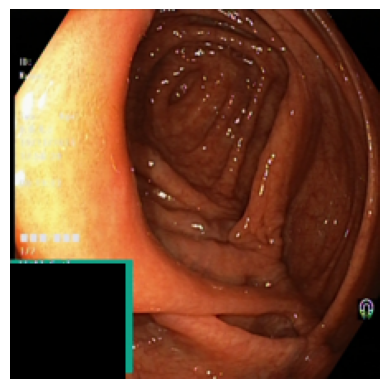

In [95]:
img_array[-70:, :70, :] = 0
plt.imshow(img_array)
plt.axis('off')
plt.show()

In [123]:
import sys
print(sys.executable)

C:\Users\docto\Python\resnet_50_endoscopy\.venv\Scripts\python.exe
